# Notebook 11 — Final Results Synthesis

## WR-MovementIQ

**Beyond the 40-Yard Dash: Linking NFL Combine Receiver Movement Mechanics to Regular-Season Performance Using Player Tracking Data**

### Purpose

This notebook consolidates independently audited outputs from the preceding analysis notebooks.

It does not train models, tune hyperparameters, change player samples, or generate new predictions.

It produces:

- Main nested-CV model comparison
- Leave-one-draft-cohort-out results
- Receiver-level bootstrap uncertainty
- Feature ablation and sensitivity summaries
- Eligibility-threshold comparisons
- Predictor association and coefficient stability summaries
- Publication-quality figures
- Final reproducibility manifest

**Important:** Results are observational and predictive. They do not establish causal relationships.


In [1]:
from pathlib import Path
import json
import hashlib
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve project root independently of notebook execution directory.
CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT_CANDIDATES = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
]

ROOT = next(
    (
        candidate
        for candidate in PROJECT_ROOT_CANDIDATES
        if (
            candidate
            / "reports"
            / "nested_ridge_modeling"
            / "nested_cv_metrics.csv"
        ).is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate WR-MovementIQ project root. "
        f"Current directory: {CURRENT_DIR}"
    )

print("Resolved project root:", ROOT)

OUT = ROOT / "reports" / "final_results_synthesis"
FIG = OUT / "figures"
TABLES = OUT / "tables"

for folder in [OUT, FIG, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Output directory:", OUT)
print("Python:", sys.version)
print("Platform:", platform.platform())


Resolved project root: D:\PROJECTS\WR-MovementIQ
Project root: D:\PROJECTS\WR-MovementIQ
Output directory: D:\PROJECTS\WR-MovementIQ\reports\final_results_synthesis
Python: 3.10.0 (tags/v3.10.0:b494f59, Oct  4 2021, 19:00:18) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-10-10.0.22621-SP0


## 1. Load and validate authoritative source artifacts

All source artifacts are loaded from their existing project locations.

Notebook 10 historical outputs are not used as authoritative results because their saved predictions and tuning artifacts failed independent reconstruction.

Notebook 10B all-threshold results are used because their complete independent reconstruction passed.


In [2]:
SOURCE_FILES = {
    "nested_cv": "reports/nested_ridge_modeling/nested_cv_metrics.csv",
    "loco": "reports/nested_ridge_modeling/loco_metrics.csv",
    "primary_decisions": (
        "reports/fold_stratified_receiver_validation/"
        "primary_speed_outcome_decisions.csv"
    ),
    "receiver_bootstrap": (
        "reports/fold_stratified_receiver_validation/"
        "fold_stratified_receiver_bootstrap.csv"
    ),
    "speed_ablation": (
        "reports/robustness_sensitivity/"
        "speed_feature_sensitivity.csv"
    ),
    "fold_stability": (
        "reports/robustness_sensitivity/"
        "sensitivity_fold_stability.csv"
    ),
    "eligibility": (
        "reports/sample_eligibility_sensitivity/"
        "eligibility_threshold_comparison.csv"
    ),
    "associations": (
        "reports/predictor_interpretation/"
        "univariate_spearman_associations.csv"
    ),
    "coefficients": (
        "reports/predictor_interpretation/"
        "coefficient_stability_summary.csv"
    ),
    "all_threshold_audit": (
        "reports/robustness_sensitivity/"
        "notebook10B_all_threshold_reconstruction_audit.csv"
    ),
}

DATA = {}
FILE_AUDIT = []

for name, relative_path in SOURCE_FILES.items():

    path = ROOT / relative_path

    if not path.is_file():
        raise FileNotFoundError(
            f"Required source artifact missing: {path}"
        )

    raw = path.read_bytes()
    digest = hashlib.sha256(raw).hexdigest()

    df = pd.read_csv(path)

    DATA[name] = df

    FILE_AUDIT.append({
        "artifact": name,
        "path": relative_path,
        "rows": len(df),
        "columns": len(df.columns),
        "sha256": digest,
        "status": "PRESENT",
    })

    print(
        f"{name:22s} "
        f"rows={len(df):6d} "
        f"columns={len(df.columns):3d}"
    )

file_audit = pd.DataFrame(FILE_AUDIT)

file_audit.to_csv(
    TABLES / "source_artifact_inventory.csv",
    index=False,
)

nested = DATA["nested_cv"]
loco = DATA["loco"]
decisions = DATA["primary_decisions"]
bootstrap = DATA["receiver_bootstrap"]
ablation = DATA["speed_ablation"]
stability = DATA["fold_stability"]
eligibility = DATA["eligibility"]
associations = DATA["associations"]
coefficients = DATA["coefficients"]
threshold_audit = DATA["all_threshold_audit"]

EXPECTED_ROWS = {
    "nested_cv": 24,
    "loco": 72,
    "primary_decisions": 6,
    "receiver_bootstrap": 18,
    "speed_ablation": 15,
    "fold_stability": 54,
    "eligibility": 300,
    "associations": 54,
    "coefficients": 108,
    "all_threshold_audit": 15,
}

for name, expected in EXPECTED_ROWS.items():

    actual = len(DATA[name])

    if actual != expected:
        raise ValueError(
            f"{name}: expected {expected} rows, found {actual}"
        )

required_audit_columns = {"pass"}

if not required_audit_columns.issubset(threshold_audit.columns):
    raise ValueError(
        "All-threshold audit is missing the required 'pass' column."
    )

audit_pass = (
    threshold_audit["pass"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

if not audit_pass.all():
    raise AssertionError(
        "At least one Notebook 10B reconstruction audit failed."
    )

print("\nSource schema and row-count checks passed.")
print("All-threshold independent reconstruction: PASS")


nested_cv              rows=    24 columns=  7
loco                   rows=    72 columns=  8
primary_decisions      rows=     6 columns= 19
receiver_bootstrap     rows=    18 columns=  8
speed_ablation         rows=    15 columns=  8
fold_stability         rows=    54 columns=  8
eligibility            rows=   300 columns= 12
associations           rows=    54 columns=  5
coefficients           rows=   108 columns= 12
all_threshold_audit    rows=    15 columns=  9

Source schema and row-count checks passed.
All-threshold independent reconstruction: PASS


## 2. Main nested cross-validation performance

The main comparison includes:

- BASELINE
- TRADITIONAL
- TRACKING
- COMBINED

The metrics are descriptive out-of-fold performance summaries across player-seasons.


,outcome,model,n,mae,rmse,r2,spearman
0,game_mean_acceleration_raw_median,BASELINE,93,0.144469,0.183763,-0.033694,-0.232272
1,game_mean_acceleration_raw_median,TRADITIONAL,93,0.147980,0.188175,-0.083928,-0.142963
2,game_mean_acceleration_raw_median,TRACKING,93,0.151695,0.192080,-0.129386,-0.275726
3,game_mean_acceleration_raw_median,COMBINED,93,0.152166,0.193057,-0.140895,-0.206106
4,game_mean_speed_raw_median,BASELINE,93,0.387971,0.509557,-0.064864,-0.331299
5,game_mean_speed_raw_median,TRADITIONAL,93,0.395478,0.512723,-0.078138,-0.100602
6,game_mean_speed_raw_median,TRACKING,93,0.405508,0.527236,-0.140036,-0.223604
7,game_mean_speed_raw_median,COMBINED,93,0.395147,0.516501,-0.094088,-0.164864
8,game_p95_speed_raw_median,BASELINE,93,0.475230,0.649344,-0.111102,-0.325232
9,game_p95_speed_raw_median,TRADITIONAL,93,0.472152,0.619673,-0.011879,0.246282


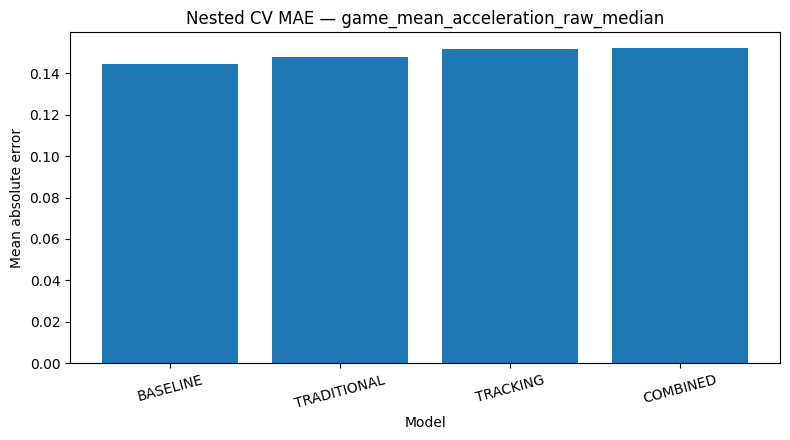

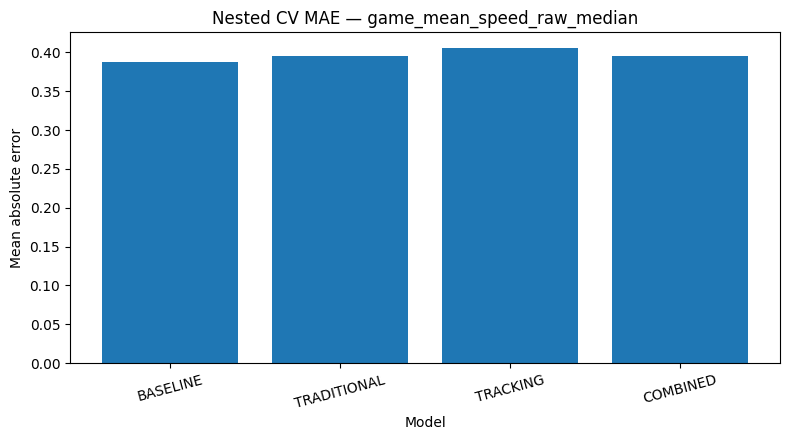

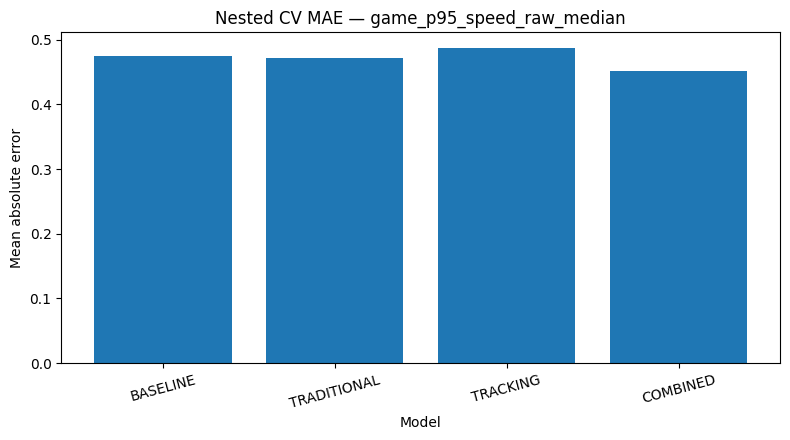

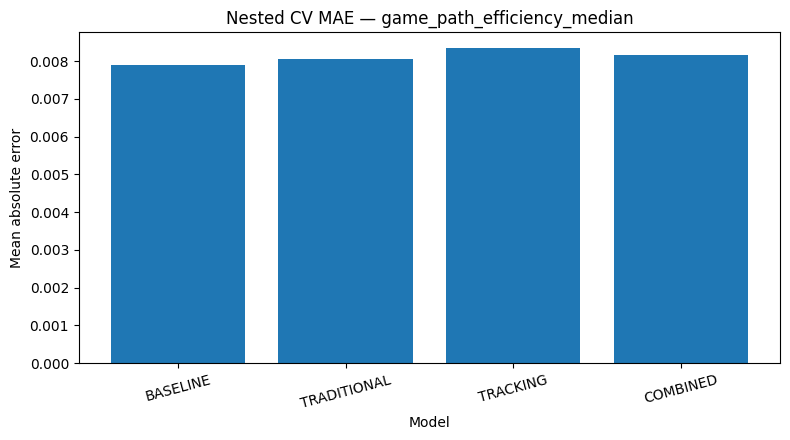

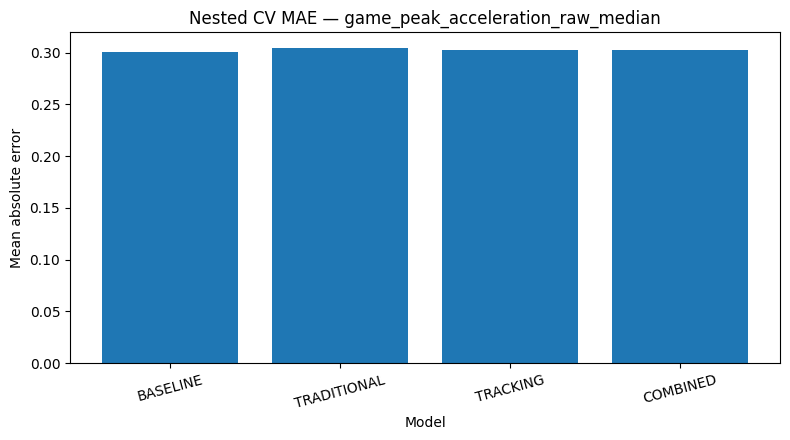

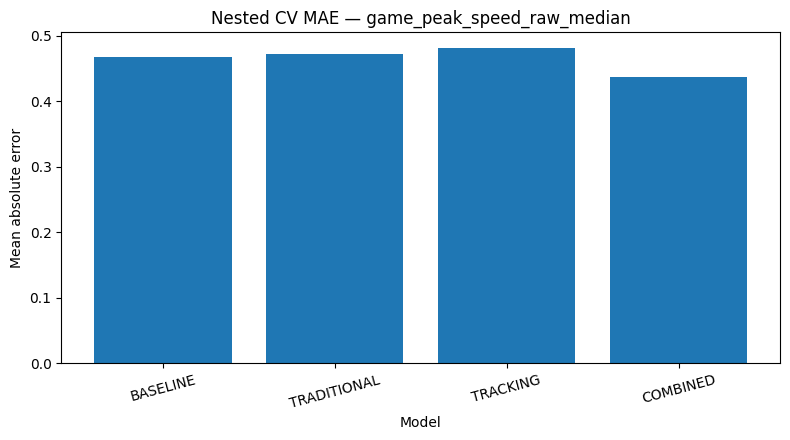


Descriptive mean metrics across outcomes:


,mae,rmse,r2
model,,,
COMBINED,0.291049,0.380112,-0.043867
BASELINE,0.297212,0.396616,-0.070304
TRADITIONAL,0.299900,0.389186,-0.054541
TRACKING,0.305954,0.402309,-0.120557


In [3]:
MODEL_ORDER = [
    "BASELINE",
    "TRADITIONAL",
    "TRACKING",
    "COMBINED",
]

nested_summary = nested.copy()

nested_summary["model"] = pd.Categorical(
    nested_summary["model"],
    categories=MODEL_ORDER,
    ordered=True,
)

for col in ["mae", "rmse", "r2"]:
    nested_summary[col] = pd.to_numeric(
        nested_summary[col],
        errors="coerce",
    )

nested_summary = nested_summary.sort_values(
    ["outcome", "model"]
)

nested_summary.to_csv(
    TABLES / "main_nested_cv_performance.csv",
    index=False,
)

display(nested_summary)

for outcome in nested_summary["outcome"].unique():

    subset = nested_summary[
        nested_summary["outcome"] == outcome
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.bar(
        subset["model"].astype(str),
        subset["mae"],
    )

    ax.set_title(f"Nested CV MAE — {outcome}")
    ax.set_ylabel("Mean absolute error")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=15)

    fig.tight_layout()

    fig.savefig(
        FIG / f"nested_mae_{outcome}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

print("\nDescriptive mean metrics across outcomes:")
display(
    nested_summary.groupby(
        "model",
        observed=True,
    )[["mae", "rmse", "r2"]]
    .mean()
    .sort_values("mae")
)


## 3. Leave-one-draft-cohort-out validation

These results evaluate how models perform when an entire draft cohort is held out.

Cohort-specific estimates should be interpreted cautiously because sample sizes differ.


,outcome,model,held_out_draft_year,n,mae,rmse,r2,spearman
0,game_mean_acceleration_raw_median,BASELINE,2023,45,0.169187,0.211680,-0.039524,NaN
3,game_mean_acceleration_raw_median,COMBINED,2023,45,0.184433,0.223885,-0.162856,0.034243
6,game_mean_acceleration_raw_median,TRACKING,2023,45,0.167578,0.210335,-0.026354,0.230199
9,game_mean_acceleration_raw_median,TRADITIONAL,2023,45,0.172289,0.213936,-0.061800,-0.063801
1,game_mean_acceleration_raw_median,BASELINE,2024,34,0.108006,0.137716,-0.000482,NaN
...,...,...,...,...,...,...,...,...
70,game_peak_speed_raw_median,TRADITIONAL,2024,34,0.504377,0.611023,-0.019779,0.175602
62,game_peak_speed_raw_median,BASELINE,2025,14,0.367500,0.442362,-0.013895,NaN
65,game_peak_speed_raw_median,COMBINED,2025,14,0.289487,0.353263,0.353401,0.643956
68,game_peak_speed_raw_median,TRACKING,2025,14,0.371552,0.458166,-0.087634,0.116484


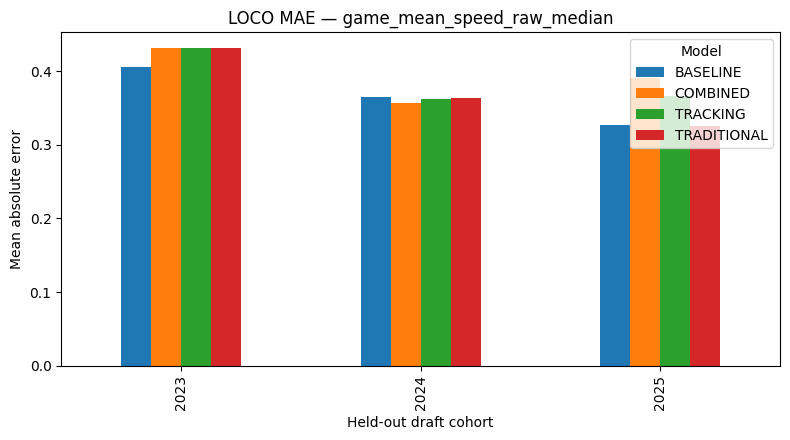

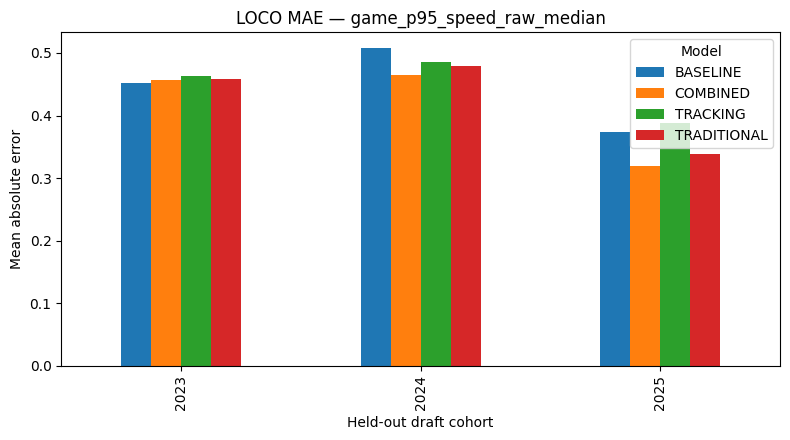

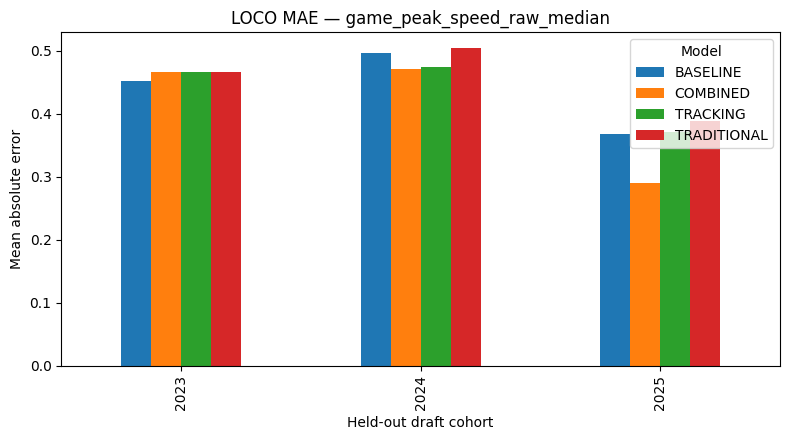

In [4]:
loco_summary = loco.copy()

for col in [
    "n",
    "mae",
    "rmse",
    "r2",
    "held_out_draft_year",
]:
    loco_summary[col] = pd.to_numeric(
        loco_summary[col],
        errors="coerce",
    )

loco_summary = loco_summary.sort_values(
    ["outcome", "held_out_draft_year", "model"]
)

loco_summary.to_csv(
    TABLES / "loco_performance.csv",
    index=False,
)

display(loco_summary)

speed_outcomes = [
    "game_mean_speed_raw_median",
    "game_p95_speed_raw_median",
    "game_peak_speed_raw_median",
]

for outcome in speed_outcomes:

    subset = loco_summary[
        loco_summary["outcome"] == outcome
    ].copy()

    pivot = subset.pivot(
        index="held_out_draft_year",
        columns="model",
        values="mae",
    )

    fig, ax = plt.subplots(figsize=(8, 4.5))

    pivot.plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(f"LOCO MAE — {outcome}")
    ax.set_ylabel("Mean absolute error")
    ax.set_xlabel("Held-out draft cohort")
    ax.legend(title="Model")

    fig.tight_layout()

    fig.savefig(
        FIG / f"loco_{outcome}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


## 4. Receiver-level bootstrap uncertainty

The bootstrap compares receiver-level model errors against the baseline.

Negative MAE differences favour the evaluated model.

Confidence intervals containing zero do not establish a reliable improvement.


,outcome,model,bootstrap_replicates,point_estimate,ci_2_5,ci_97_5,probability_difference_below_zero,interpretation
0,game_mean_acceleration_raw_median,TRADITIONAL,5000,0.004559,-0.002151,0.011237,0.0984,UNCERTAIN_CI_INCLUDES_ZERO
1,game_mean_acceleration_raw_median,TRACKING,5000,0.009606,0.001865,0.018030,0.0066,CANDIDATE_HIGHER_MAE
2,game_mean_acceleration_raw_median,COMBINED,5000,0.008938,-0.000630,0.019037,0.0358,UNCERTAIN_CI_INCLUDES_ZERO
3,game_mean_speed_raw_median,TRADITIONAL,5000,0.015918,-0.003484,0.035858,0.0566,UNCERTAIN_CI_INCLUDES_ZERO
4,game_mean_speed_raw_median,TRACKING,5000,0.025316,0.003362,0.045889,0.0112,CANDIDATE_HIGHER_MAE
5,game_mean_speed_raw_median,COMBINED,5000,0.016582,-0.004641,0.037746,0.0644,UNCERTAIN_CI_INCLUDES_ZERO
6,game_p95_speed_raw_median,TRADITIONAL,5000,0.012620,-0.034641,0.060452,0.2980,UNCERTAIN_CI_INCLUDES_ZERO
7,game_p95_speed_raw_median,TRACKING,5000,0.018873,-0.015015,0.055040,0.1336,UNCERTAIN_CI_INCLUDES_ZERO
8,game_p95_speed_raw_median,COMBINED,5000,-0.007547,-0.067782,0.054371,0.5966,UNCERTAIN_CI_INCLUDES_ZERO
9,game_path_efficiency_median,TRADITIONAL,5000,0.000197,-0.000199,0.000597,0.1624,UNCERTAIN_CI_INCLUDES_ZERO


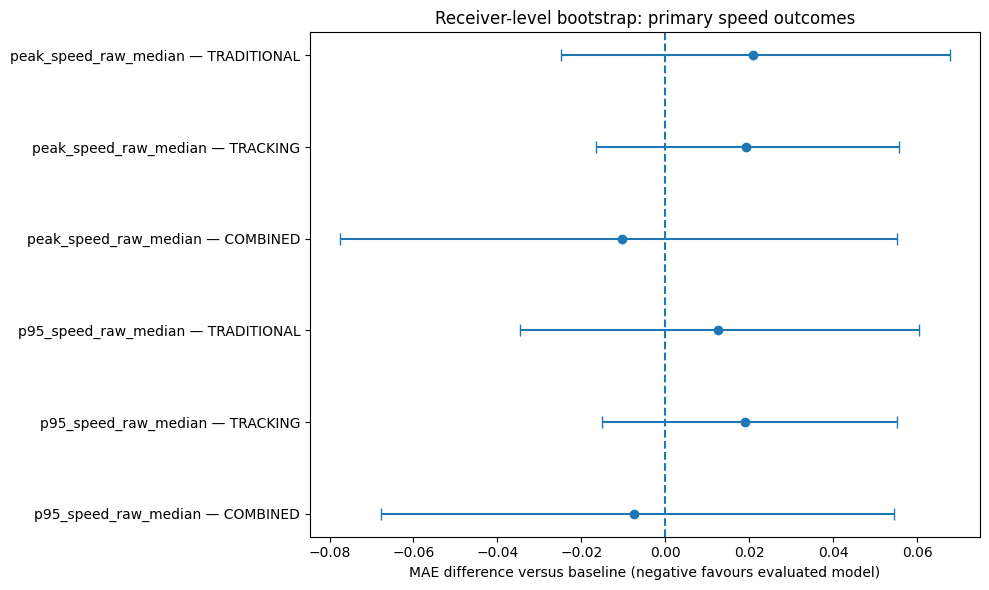

In [5]:
bootstrap_summary = bootstrap.copy()

numeric_cols = [
    "point_estimate",
    "ci_2_5",
    "ci_97_5",
    "probability_difference_below_zero",
]

for col in numeric_cols:

    if col in bootstrap_summary.columns:
        bootstrap_summary[col] = pd.to_numeric(
            bootstrap_summary[col],
            errors="coerce",
        )

bootstrap_summary.to_csv(
    TABLES / "receiver_level_bootstrap_summary.csv",
    index=False,
)

display(bootstrap_summary)

primary = decisions.copy()

for col in [
    "point_estimate",
    "ci_2_5",
    "ci_97_5",
    "probability_difference_below_zero",
]:
    if col in primary.columns:
        primary[col] = pd.to_numeric(
            primary[col],
            errors="coerce",
        )

primary.to_csv(
    TABLES / "primary_speed_outcome_decisions.csv",
    index=False,
)

required_plot_columns = {
    "outcome",
    "model",
    "point_estimate",
    "ci_2_5",
    "ci_97_5",
}

if not required_plot_columns.issubset(primary.columns):
    raise ValueError(
        "Primary decision table does not contain the required "
        "confidence interval plotting columns. "
        f"Available columns: {list(primary.columns)}"
    )

plot_data = primary.copy()

plot_data["label"] = (
    plot_data["outcome"].astype(str)
    .str.replace("game_", "", regex=False)
    + " — "
    + plot_data["model"].astype(str)
)

plot_data = plot_data.sort_values(
    ["outcome", "model"]
)

y = np.arange(len(plot_data))

x = plot_data["point_estimate"].to_numpy(dtype=float)

lower_error = (
    x - plot_data["ci_2_5"].to_numpy(dtype=float)
)

upper_error = (
    plot_data["ci_97_5"].to_numpy(dtype=float) - x
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    x,
    y,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=4,
)

ax.axvline(
    0,
    linestyle="--",
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["label"])

ax.set_xlabel(
    "MAE difference versus baseline "
    "(negative favours evaluated model)"
)

ax.set_title(
    "Receiver-level bootstrap: primary speed outcomes"
)

fig.tight_layout()

fig.savefig(
    FIG / "primary_speed_bootstrap_intervals.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


## 5. Feature ablation and fold stability

These analyses examine whether individual tracking-feature groups contribute consistently.

Point estimates should be considered alongside fold-to-fold variability.


,outcome,model,observations,receivers,mae,rmse,r2,pearson
0,game_mean_speed_raw_median,COMBINED_FULL,93,54,0.395147,0.516501,-0.094088,-0.140085
1,game_mean_speed_raw_median,COMBINED_NO_P95_SPEED,93,54,0.394881,0.516205,-0.092834,-0.160637
2,game_mean_speed_raw_median,COMBINED_NO_PEAK_SPEED,93,54,0.394572,0.516492,-0.094046,-0.166971
3,game_mean_speed_raw_median,COMBINED_P95_SPEED_ONLY,93,54,0.391755,0.512912,-0.078932,-0.107287
4,game_mean_speed_raw_median,COMBINED_PEAK_SPEED_ONLY,93,54,0.391753,0.512726,-0.078151,-0.099684
5,game_p95_speed_raw_median,COMBINED_FULL,93,54,0.451680,0.598202,0.057028,0.292619
6,game_p95_speed_raw_median,COMBINED_NO_P95_SPEED,93,54,0.447984,0.591623,0.077655,0.307476
7,game_p95_speed_raw_median,COMBINED_NO_PEAK_SPEED,93,54,0.451194,0.596805,0.061424,0.296186
8,game_p95_speed_raw_median,COMBINED_P95_SPEED_ONLY,93,54,0.449119,0.616804,-0.002530,0.149865
9,game_p95_speed_raw_median,COMBINED_PEAK_SPEED_ONLY,93,54,0.456572,0.618570,-0.008281,0.174220


,outcome,model,mean_mae_difference,median_mae_difference,folds_better,folds_worse,minimum_difference,maximum_difference
0,game_mean_acceleration_raw_median,COMBINED_FULL,0.007526,0.000311,2,3,-0.001103,0.037994
1,game_mean_acceleration_raw_median,COMBINED_NO_ACCELERATION,-0.000289,-0.000674,3,2,-0.001185,0.001224
2,game_mean_acceleration_raw_median,COMBINED_NO_P95_SPEED,0.007719,0.000316,2,3,-0.001563,0.039401
3,game_mean_acceleration_raw_median,COMBINED_NO_PEAK_SPEED,0.007068,0.000316,2,3,-0.001567,0.036152
4,game_mean_acceleration_raw_median,COMBINED_P95_SPEED_ONLY,0.001418,0.000276,2,3,-0.001471,0.007860
5,game_mean_acceleration_raw_median,COMBINED_PEAK_SPEED_ONLY,0.001544,0.000315,2,3,-0.001435,0.008414
6,game_mean_acceleration_raw_median,TRACKING_FULL,0.007060,0.000311,2,3,-0.001558,0.035292
7,game_mean_acceleration_raw_median,TRACKING_SPEED_ONLY,-0.000291,-0.000673,3,2,-0.001770,0.001791
8,game_mean_acceleration_raw_median,TRADITIONAL,0.003637,0.000320,2,3,-0.001269,0.018700
9,game_mean_speed_raw_median,COMBINED_FULL,0.007308,-0.002663,3,2,-0.036550,0.051109


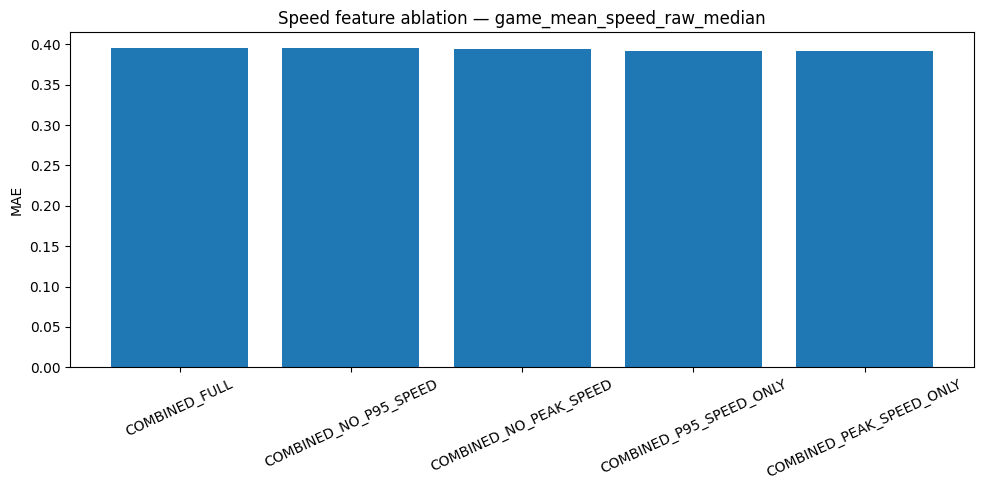

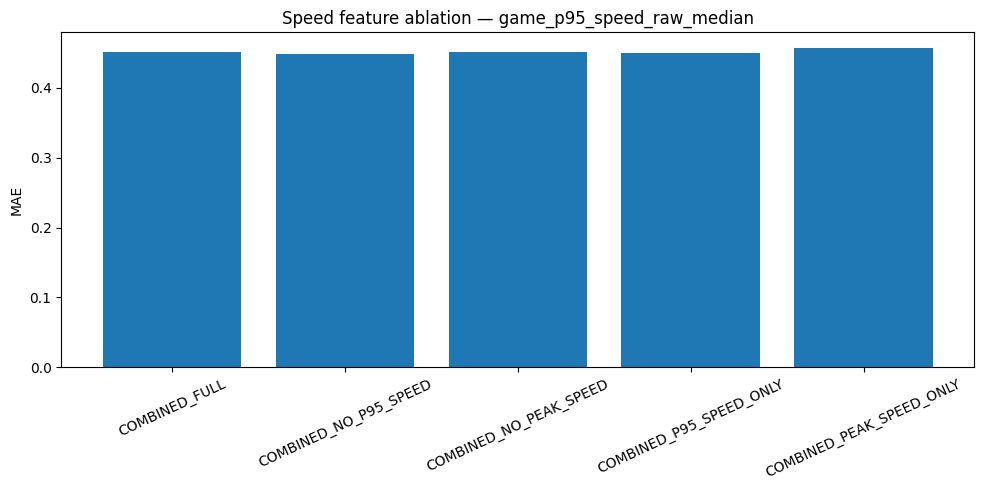

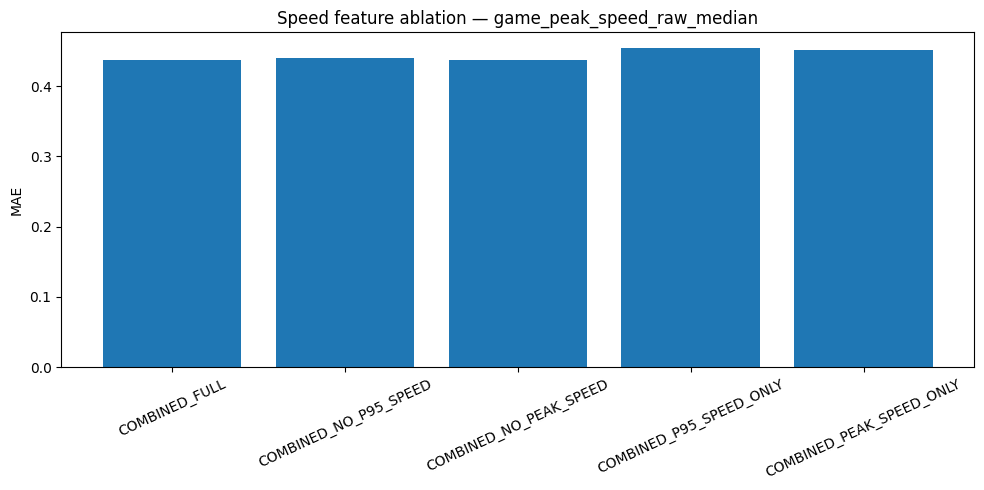

In [6]:
ablation_summary = ablation.copy()
stability_summary = stability.copy()

ablation_summary.to_csv(
    TABLES / "speed_feature_ablation.csv",
    index=False,
)

stability_summary.to_csv(
    TABLES / "sensitivity_fold_stability.csv",
    index=False,
)

display(ablation_summary)
display(stability_summary)

for outcome in speed_outcomes:

    subset = ablation_summary[
        ablation_summary["outcome"] == outcome
    ].copy()

    subset["mae"] = pd.to_numeric(
        subset["mae"],
        errors="coerce",
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(
        subset["model"].astype(str),
        subset["mae"],
    )

    ax.set_title(
        f"Speed feature ablation — {outcome}"
    )

    ax.set_ylabel("MAE")
    ax.tick_params(axis="x", rotation=25)

    fig.tight_layout()

    fig.savefig(
        FIG / f"ablation_{outcome}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


## 6. Sample eligibility sensitivity

This section compares model results across minimum receiver-play eligibility thresholds.

The threshold analysis uses the independently reconstructed Notebook 10B outputs.


,threshold,outcome,model,player_seasons,unique_receivers,mae,rmse,r2,ten_play_mae,ten_play_rmse,mae_change_vs_10,rmse_change_vs_10
0,5,game_mean_acceleration_raw_median,BASELINE,93.0,54.0,0.144469,0.183763,-0.033694,0.144469,0.183763,0.000000,0.000000
60,8,game_mean_acceleration_raw_median,BASELINE,93.0,54.0,0.144469,0.183763,-0.033694,0.144469,0.183763,0.000000,0.000000
120,10,game_mean_acceleration_raw_median,BASELINE,93.0,54.0,0.144469,0.183763,-0.033694,0.144469,0.183763,0.000000,0.000000
180,12,game_mean_acceleration_raw_median,BASELINE,92.0,53.0,0.142907,0.182062,-0.034386,0.144469,0.183763,-0.001562,-0.001701
240,15,game_mean_acceleration_raw_median,BASELINE,83.0,48.0,0.142127,0.179955,-0.041795,0.144469,0.183763,-0.002343,-0.003808
1,5,game_mean_acceleration_raw_median,COMBINED_FULL,93.0,54.0,0.144045,0.184318,-0.039945,0.144045,0.184318,0.000000,0.000000
61,8,game_mean_acceleration_raw_median,COMBINED_FULL,93.0,54.0,0.144045,0.184318,-0.039945,0.144045,0.184318,0.000000,0.000000
121,10,game_mean_acceleration_raw_median,COMBINED_FULL,93.0,54.0,0.144045,0.184318,-0.039945,0.144045,0.184318,0.000000,0.000000
181,12,game_mean_acceleration_raw_median,COMBINED_FULL,92.0,53.0,0.145272,0.185275,-0.071217,0.144045,0.184318,0.001227,0.000957
241,15,game_mean_acceleration_raw_median,COMBINED_FULL,83.0,48.0,0.143687,0.183195,-0.079645,0.144045,0.184318,-0.000358,-0.001122


,threshold,player_seasons,unique_receivers
0,5,93.0,54.0
60,8,93.0,54.0
120,10,93.0,54.0
180,12,92.0,53.0
240,15,83.0,48.0


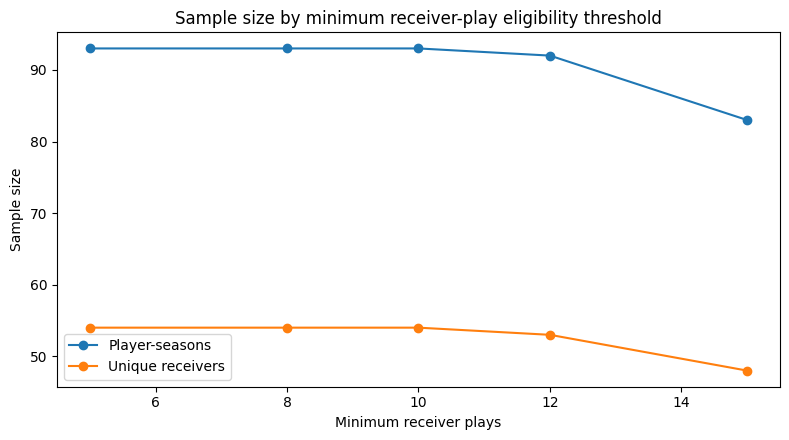

Eligibility sensitivity and independent reconstruction audit exported.


In [7]:
eligibility_summary = eligibility.copy()

for col in [
    "threshold",
    "player_seasons",
    "unique_receivers",
    "mae",
    "rmse",
    "r2",
]:
    if col in eligibility_summary.columns:
        eligibility_summary[col] = pd.to_numeric(
            eligibility_summary[col],
            errors="coerce",
        )

eligibility_summary = eligibility_summary.sort_values(
    ["outcome", "model", "threshold"]
)

eligibility_summary.to_csv(
    TABLES / "eligibility_threshold_comparison.csv",
    index=False,
)

display(eligibility_summary.head(30))

required_sample_columns = {
    "threshold",
    "player_seasons",
    "unique_receivers",
}

if not required_sample_columns.issubset(
    eligibility_summary.columns
):
    raise ValueError(
        "Eligibility table lacks sample-size columns. "
        f"Available columns: {list(eligibility_summary.columns)}"
    )

sample_sizes = (
    eligibility_summary[
        ["threshold", "player_seasons", "unique_receivers"]
    ]
    .drop_duplicates()
    .sort_values("threshold")
)

display(sample_sizes)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    sample_sizes["threshold"],
    sample_sizes["player_seasons"],
    marker="o",
    label="Player-seasons",
)

ax.plot(
    sample_sizes["threshold"],
    sample_sizes["unique_receivers"],
    marker="o",
    label="Unique receivers",
)

ax.set_title(
    "Sample size by minimum receiver-play eligibility threshold"
)

ax.set_xlabel("Minimum receiver plays")
ax.set_ylabel("Sample size")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG / "eligibility_sample_sizes.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

threshold_audit.to_csv(
    TABLES / "notebook10B_all_threshold_reconstruction_audit.csv",
    index=False,
)

print("Eligibility sensitivity and independent reconstruction audit exported.")


## 7. Predictor associations and coefficient stability

Univariate Spearman associations describe marginal relationships.

They must not be interpreted as independent predictor effects or causal effects.


,outcome,predictor,group,n,spearman_rho
32,game_mean_acceleration_raw_median,combine_p95_speed_median_across_drills,TRACKING,93,-0.185750
31,game_mean_acceleration_raw_median,combine_peak_speed_median_across_drills,TRACKING,93,-0.174995
27,game_mean_acceleration_raw_median,forty,TRADITIONAL,93,0.150436
28,game_mean_acceleration_raw_median,vertical,TRADITIONAL,93,-0.091479
34,game_mean_acceleration_raw_median,combine_peak_acceleration_median_across_drills,TRACKING,93,0.060703
33,game_mean_acceleration_raw_median,combine_mean_acceleration_median_across_drills,TRACKING,93,0.059882
30,game_mean_acceleration_raw_median,combine_mean_speed_median_across_drills,TRACKING,93,0.043108
29,game_mean_acceleration_raw_median,broad_jump,TRADITIONAL,93,0.028449
35,game_mean_acceleration_raw_median,combine_path_efficiency_median_across_drills,TRACKING,93,0.009633
4,game_mean_speed_raw_median,combine_peak_speed_median_across_drills,TRACKING,93,0.270384


,outcome,model,predictor,folds,mean_coefficient,median_coefficient,coefficient_sd,minimum,maximum,positive_folds,negative_folds,sign_consistency
0,game_mean_acceleration_raw_median,COMBINED,broad_jump,5,0.005144,-0.000004,0.011711,-0.000364,0.026091,1,4,0.8
1,game_mean_acceleration_raw_median,COMBINED,combine_mean_acceleration_median_across_drills,5,0.007712,0.000003,0.016890,-0.000008,0.037921,3,2,0.6
2,game_mean_acceleration_raw_median,COMBINED,combine_mean_speed_median_across_drills,5,0.005089,0.000015,0.011225,-0.000016,0.025169,4,1,0.8
3,game_mean_acceleration_raw_median,COMBINED,combine_p95_speed_median_across_drills,5,-0.002834,-0.000029,0.004894,-0.011321,-0.000010,0,5,1.0
4,game_mean_acceleration_raw_median,COMBINED,combine_path_efficiency_median_across_drills,5,0.009756,0.000017,0.021080,0.000004,0.047453,5,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
103,game_peak_speed_raw_median,TRACKING,combine_peak_acceleration_median_across_drills,5,-0.014258,0.000828,0.035780,-0.078045,0.005953,3,2,0.6
104,game_peak_speed_raw_median,TRACKING,combine_peak_speed_median_across_drills,5,0.050512,0.011111,0.074063,0.005105,0.179873,5,0,1.0
105,game_peak_speed_raw_median,TRADITIONAL,broad_jump,5,-0.002277,-0.000720,0.021351,-0.024819,0.027065,2,3,0.6
106,game_peak_speed_raw_median,TRADITIONAL,forty,5,-0.186539,-0.238130,0.095440,-0.279626,-0.059036,0,5,1.0


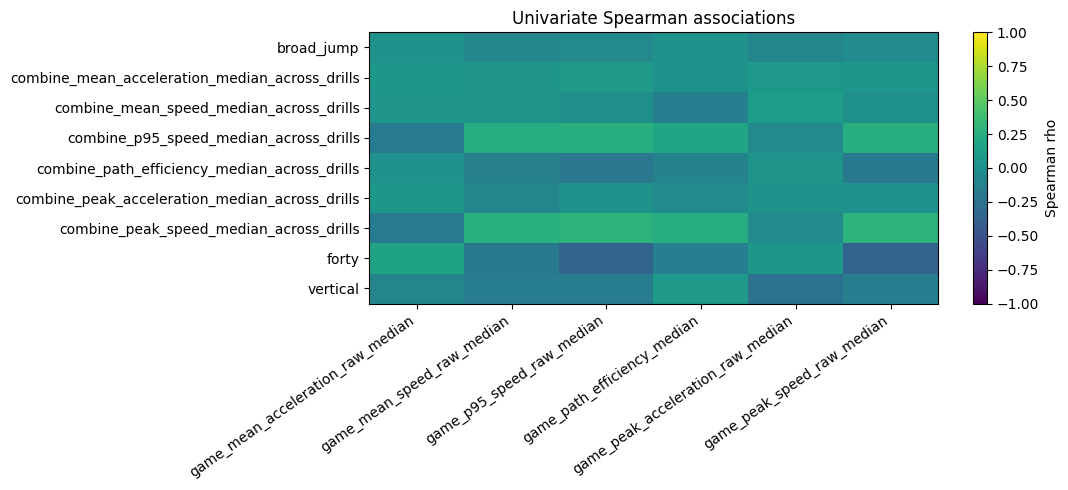

,outcome,model,mean_coefficient_sd
0,game_mean_acceleration_raw_median,COMBINED,1.354198e-02
1,game_mean_acceleration_raw_median,TRACKING,1.324409e-02
2,game_mean_acceleration_raw_median,TRADITIONAL,1.019946e-02
3,game_mean_speed_raw_median,COMBINED,1.309291e-02
4,game_mean_speed_raw_median,TRACKING,2.968607e-02
5,game_mean_speed_raw_median,TRADITIONAL,2.224448e-02
6,game_p95_speed_raw_median,COMBINED,4.573700e-02
7,game_p95_speed_raw_median,TRACKING,3.391316e-02
8,game_p95_speed_raw_median,TRADITIONAL,6.554070e-02
9,game_path_efficiency_median,COMBINED,8.260149e-04


In [8]:
association_summary = associations.copy()

if "spearman_rho" not in association_summary.columns:
    raise ValueError(
        "Missing spearman_rho in association source. "
        f"Columns: {list(association_summary.columns)}"
    )

association_summary["spearman_rho"] = pd.to_numeric(
    association_summary["spearman_rho"],
    errors="coerce",
)

association_summary = association_summary.sort_values(
    ["outcome", "spearman_rho"],
    key=lambda s: (
        s.abs()
        if s.name == "spearman_rho"
        else s
    ),
    ascending=[True, False],
)

association_summary.to_csv(
    TABLES / "univariate_spearman_associations.csv",
    index=False,
)

coefficient_summary = coefficients.copy()

coefficient_summary.to_csv(
    TABLES / "coefficient_stability_summary.csv",
    index=False,
)

display(association_summary)
display(coefficient_summary)

required_heatmap_columns = {
    "predictor",
    "outcome",
    "spearman_rho",
}

if not required_heatmap_columns.issubset(
    association_summary.columns
):
    raise ValueError(
        "Association table is missing heatmap columns. "
        f"Columns: {list(association_summary.columns)}"
    )

heat = association_summary.pivot(
    index="predictor",
    columns="outcome",
    values="spearman_rho",
)

fig, ax = plt.subplots(
    figsize=(11, max(5, 0.45 * len(heat)))
)

im = ax.imshow(
    heat.to_numpy(dtype=float),
    aspect="auto",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    np.arange(len(heat.columns))
)

ax.set_xticklabels(
    heat.columns,
    rotation=35,
    ha="right",
)

ax.set_yticks(
    np.arange(len(heat.index))
)

ax.set_yticklabels(
    heat.index
)

ax.set_title(
    "Univariate Spearman associations"
)

fig.colorbar(
    im,
    ax=ax,
    label="Spearman rho",
)

fig.tight_layout()

fig.savefig(
    FIG / "predictor_spearman_heatmap.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

if "coefficient_sd" in coefficient_summary.columns:

    coefficient_summary["coefficient_sd"] = pd.to_numeric(
        coefficient_summary["coefficient_sd"],
        errors="coerce",
    )

    display(
        coefficient_summary.groupby(
            ["outcome", "model"]
        )["coefficient_sd"]
        .mean()
        .rename("mean_coefficient_sd")
        .reset_index()
    )


## 8. Research interpretation

The following interpretation is deliberately conservative.

It reflects the observed results and their limitations rather than treating favourable point estimates as established improvements.


In [9]:
interpretation = {
    "research_question": (
        "To what extent do movement characteristics measured during "
        "NFL Combine receiver-specific drills explain variation in "
        "wide receivers' in-game movement characteristics?"
    ),

    "main_findings": [
        (
            "Traditional and tracking-derived Combine measures show "
            "some associations with in-game movement outcomes."
        ),
        (
            "Tracking-derived features do not demonstrate consistent, "
            "convincing incremental improvement in absolute predictive accuracy."
        ),
        (
            "Some combined models have favourable point estimates for peak "
            "and 95th-percentile game speed, but receiver-level uncertainty "
            "intervals include zero."
        ),
        (
            "Predictor coefficient magnitudes and signs vary across folds, "
            "limiting claims about stable independent feature effects."
        ),
        (
            "Eligibility sensitivity is independently reconstructed across "
            "all five thresholds."
        ),
    ],

    "limitations": [
        (
            "The primary modeling sample contains 93 player-seasons "
            "from 54 receivers."
        ),
        (
            "The sample is small relative to the complexity of NFL "
            "receiver performance."
        ),
        (
            "Complete-case requirements reduce the available sample."
        ),
        (
            "Draft cohorts have unequal sample sizes."
        ),
        (
            "Combine speed predictors are strongly correlated."
        ),
        (
            "Regularized coefficients are sensitive to the training "
            "fold and penalty."
        ),
        (
            "Observational associations do not establish causal effects."
        ),
        (
            "LOCO estimates are cohort-specific and should not be "
            "interpreted as definitive evidence of future-season "
            "generalization."
        ),
    ],

    "interpretation_guardrails": [
        (
            "Do not describe an uncertain point estimate as a proven gain."
        ),
        (
            "Do not interpret negative R-squared as a negative correlation."
        ),
        (
            "Do not describe univariate Spearman associations as "
            "independent effects."
        ),
        (
            "Do not infer causal effects from predictive associations."
        ),
        (
            "Do not claim robust generalization from a small held-out cohort."
        ),
    ],
}

interpretation_path = OUT / "research_interpretation.json"

interpretation_path.write_text(
    json.dumps(
        interpretation,
        indent=2,
    ),
    encoding="utf-8",
)

for heading, items in interpretation.items():

    print(f"\n{heading.upper()}")

    if isinstance(items, list):

        for item in items:
            print("-", item)

    else:
        print(items)



RESEARCH_QUESTION
To what extent do movement characteristics measured during NFL Combine receiver-specific drills explain variation in wide receivers' in-game movement characteristics?

MAIN_FINDINGS
- Traditional and tracking-derived Combine measures show some associations with in-game movement outcomes.
- Tracking-derived features do not demonstrate consistent, convincing incremental improvement in absolute predictive accuracy.
- Some combined models have favourable point estimates for peak and 95th-percentile game speed, but receiver-level uncertainty intervals include zero.
- Predictor coefficient magnitudes and signs vary across folds, limiting claims about stable independent feature effects.
- Eligibility sensitivity is independently reconstructed across all five thresholds.

LIMITATIONS
- The primary modeling sample contains 93 player-seasons from 54 receivers.
- The sample is small relative to the complexity of NFL receiver performance.
- Complete-case requirements reduce the 

## 9. Reproducibility manifest and final audit

This final section records the source artifact hashes, audit status, execution environment and generated outputs.

The manifest provides an auditable record of the synthesis.


In [10]:
manifest = {
    "project": "WR-MovementIQ",

    "notebook": "11_final_results_synthesis.ipynb",

    "generated_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "python_version": sys.version,

    "platform": platform.platform(),

    "analysis_type": (
        "Results synthesis; no model refitting."
    ),

    "primary_dataset_sha256": (
        "02fbd802522973f7c4d100da57cd680f7bbfde6346a0431a7aa1fe5e25807c5c"
    ),

    "notebook10_status": (
        "Historical outputs retained for provenance but not authoritative "
        "because saved tuning and prediction artifacts failed independent "
        "reconstruction."
    ),

    "notebook10B_status": (
        "PASS: all-threshold independent reconstruction."
    ),

    "threshold_audit_checks": int(
        len(threshold_audit)
    ),

    "threshold_audit_passes": int(
        audit_pass.sum()
    ),

    "threshold_audit_failures": int(
        (~audit_pass).sum()
    ),

    "source_artifacts": FILE_AUDIT,

    "outputs": [],
}

assert manifest["threshold_audit_failures"] == 0

assert manifest["threshold_audit_checks"] == 15

manifest_path = OUT / "final_results_manifest.json"

# Capture all generated artifacts before writing the manifest.
for path in sorted(OUT.rglob("*")):

    if (
        path.is_file()
        and path.name != "final_results_manifest.json"
    ):

        manifest["outputs"].append({
            "path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(
                path.read_bytes()
            ).hexdigest(),
        })

manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

file_audit.to_csv(
    OUT / "source_artifact_inventory.csv",
    index=False,
)

print("\n" + "=" * 80)
print("NOTEBOOK 11 SYNTHESIS COMPLETE")
print("=" * 80)

print("Source artifacts:", len(FILE_AUDIT))
print("Nested CV rows:", len(nested))
print("LOCO rows:", len(loco))
print("Bootstrap rows:", len(bootstrap))
print("Eligibility comparison rows:", len(eligibility))

print(
    "Independent threshold audit:",
    "PASS" if audit_pass.all() else "FAIL",
)

print(
    "Figures:",
    len(list(FIG.glob("*.png"))),
)

print(
    "Tables:",
    len(list(TABLES.glob("*.csv"))),
)

print("Manifest:", manifest_path)



NOTEBOOK 11 SYNTHESIS COMPLETE
Source artifacts: 10
Nested CV rows: 24
LOCO rows: 72
Bootstrap rows: 18
Eligibility comparison rows: 300
Independent threshold audit: PASS
Figures: 15
Tables: 11
Manifest: D:\PROJECTS\WR-MovementIQ\reports\final_results_synthesis\final_results_manifest.json
